# 17 — Train-Only Regional Lock & 0.25° Fine-Grid Dataset Construction

## Why this notebook exists

Notebook 16 showed that a finer regional grid can reveal many more spatially localized **Emerging** detections. Before using that region for modeling, however, two methodological issues must be handled explicitly.

### Gate A — verify the old 272 → 90-cell correction

The corrected Kalimantan domain reduced the rectangular 272-cell grid to 90 valid Indonesian-Kalimantan nodes. This notebook checks whether that correction removed meaningful historical fire signal, rather than assuming that every excluded grid cell was harmless.

### Gate B — lock the regional study area using **training data only**

Notebook 16 selected its candidate region using May–September data. That is useful exploratory analysis, but it must **not** be the final domain-selection rule if August is validation and September is test.

Therefore this notebook recomputes the regional candidates using only:

```text
2026-05-01 → 2026-07-31
```

and locks the final regional bounding box before any August/September label evaluation.

---

## Main dataset constructed here

- study area: **train-only selected high-activity Kalimantan subregion**;
- fire grid: **0.25°**;
- physical mask: Indonesian Kalimantan land geometry + optional JRC Global Surface Water permanent-water screen;
- fire source: FIRMS VIIRS-SNPP hourly files aggregated to cell-day;
- weather: **ERA5 0.25°** requested directly at regional node centers;
- forecasting target: next-day FIRMS-detected fire-active cell;
- fire-history features: same 10 benchmark features used previously;
- weather features: same 10 benchmark concepts used previously;
- validation: August remains evaluation-only;
- final September model evaluation: **not performed here**.

---

## Important interpretation

`fire_active = 0` means **no FIRMS detection was observed in that cell-day**, not confirmed absence of fire.

Water masking is based on physical geography, **not** on whether a cell happened to have zero FIRMS detections during the season.

## Methodological decisions before running

### 1. Is the 75% August base rate a problem?

It is not automatically an error, but it **must be audited** because PR-AUC is prevalence-sensitive. The corrected-domain PR-AUC must never be described as a direct improvement over the old rectangular-domain PR-AUC without noting that the evaluation population changed.

### 2. Must the 272 → 90-cell mask be verified?

**Yes.** This notebook includes that check as a preflight gate. The key question is not merely how many cells were removed, but how much actual FIRMS signal was retained.

### 3. Must GAT attention be checked before constructing this dataset?

Useful, but **not a blocking requirement**. Notebook 14 saved average August attention by static edge and distance. That output can show whether attention is concentrated or distance-related, but it cannot establish that attention follows the daily upwind direction because the saved attention is averaged over time and does not include edge-day wind alignment.

A proper *attention vs wind alignment* diagnostic should be done later with the final regional temporal graph.

### 4. Do not use zero-fire-history as a land/water mask

A cell with zero FIRMS detections is not necessarily water or non-flammable. Physical water masking is kept independent from the forecasting labels.

## Environment

Notebook 17 requires the geospatial packages already used by Notebook 16. `rasterio` is optional but strongly recommended for the JRC Global Surface Water screen.

In the VS Code terminal:

```bash
python -m pip install geopandas shapely pyogrio requests folium rasterio
```

Then restart the notebook kernel.

In [109]:
# 1. Imports

from pathlib import Path
import json
import math
import re
import time
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import geopandas as gpd
    from shapely.geometry import Point, box
except ImportError as exc:
    raise ImportError(
        "Install geospatial dependencies first: "
        "python -m pip install geopandas shapely pyogrio"
    ) from exc

try:
    import requests
except ImportError as exc:
    raise ImportError(
        "Install requests first: python -m pip install requests"
    ) from exc

try:
    import rasterio
    from rasterio.windows import from_bounds as raster_window_from_bounds
    RASTERIO_AVAILABLE = True
except ImportError:
    RASTERIO_AVAILABLE = False

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)

print("geopandas :", gpd.__version__)
print("rasterio available:", RASTERIO_AVAILABLE)

geopandas : 1.1.4
rasterio available: True


# PART A — Resolve project paths

In [110]:
# 2. Project root and output paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    corrected_nodes = (
        candidate
        / "data"
        / "intermediate"
        / "spatial_corrected"
        / "kalimantan_graph_nodes_corrected.csv"
    )

    if corrected_nodes.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not detect skripsi-karhut project root."
    )

NB12_RESULTS = (
    PROJECT_ROOT
    / "model_results"
    / "spatial_domain_correction"
)

NB14_RESULTS = (
    PROJECT_ROOT
    / "model_results"
    / "static_graph_baseline"
)

NB16_RESULTS = (
    PROJECT_ROOT
    / "model_results"
    / "regional_zoom_selection"
)

REGIONAL_INTERMEDIATE = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "regional_025"
)

REGIONAL_PROCESSED = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
)

FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_DIR = RESULTS_DIR / "exports"
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external"
NE_DIR = EXTERNAL_DIR / "natural_earth"
JRC_DIR = EXTERNAL_DIR / "jrc_gsw_v1_4_2021"
WEATHER_BATCH_DIR = REGIONAL_INTERMEDIATE / "weather_batches"

for directory in [
    REGIONAL_INTERMEDIATE,
    REGIONAL_PROCESSED,
    RESULTS_DIR,
    FIGURES_DIR,
    EXPORT_DIR,
    EXTERNAL_DIR,
    NE_DIR,
    JRC_DIR,
    WEATHER_BATCH_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT         :", PROJECT_ROOT)
print("REGIONAL_INTERMEDIATE:", REGIONAL_INTERMEDIATE)
print("REGIONAL_PROCESSED   :", REGIONAL_PROCESSED)
print("RESULTS_DIR          :", RESULTS_DIR)

PROJECT_ROOT         : c:\Users\Asus\Documents\skripsi-karhut
REGIONAL_INTERMEDIATE: c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\regional_025
REGIONAL_PROCESSED   : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025
RESULTS_DIR          : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset


# PART B — Preflight Gate A: audit the 272 → 90-cell correction

The old rectangle contained many ocean / non-Indonesian / non-Borneo grid cells. A large reduction in node count does **not** by itself prove that important fire signal was discarded.

The strongest direct sanity check is the raw FIRMS point retention after applying the Indonesian-Kalimantan polygon.

In [111]:
# 3. Load Notebook 12B correction summaries

SPATIAL_FILTER_PATH = NB12_RESULTS / "raw_firms_spatial_filter_summary.csv"
DOMAIN_COMPARE_PATH = NB12_RESULTS / "original_vs_corrected_summary.csv"
THRESHOLD_PATH = NB12_RESULTS / "node_overlap_threshold_sensitivity.csv"
MASK_COMPARE_PATH = NB12_RESULTS / "notebook12_vs_corrected_mask.csv"

required_preflight = [
    SPATIAL_FILTER_PATH,
    DOMAIN_COMPARE_PATH,
    THRESHOLD_PATH,
]

missing_preflight = [
    p for p in required_preflight if not p.exists()
]

if missing_preflight:
    raise FileNotFoundError(
        "Notebook 12B outputs are missing. Rerun corrected Notebook 12B first:\n"
        + "\n".join(str(p) for p in missing_preflight)
    )

spatial_filter_summary = pd.read_csv(SPATIAL_FILTER_PATH)
domain_compare = pd.read_csv(DOMAIN_COMPARE_PATH)
threshold_summary = pd.read_csv(THRESHOLD_PATH)

print("Spatial filter summary")
display(spatial_filter_summary)

print("\nOriginal vs corrected domain")
display(domain_compare)

print("\nNode-mask sensitivity")
display(threshold_summary)

Spatial filter summary


,raw_firms_points,retained_kalimantan_points,removed_outside_kalimantan_points,retention_rate,default_overlap_threshold,original_grid_cells,corrected_valid_cells,corrected_excluded_cells,max_assignment_distance_km,assignments_over_100km
0,146314,139626,6688,0.95429,0.2,272,90,182,73.214863,0



Original vs corrected domain


,Version,Cells,Panel rows,Total fire detections,Active cell-days,Model-window rows,Model-window positives
0,Original rectangular domain,272,36448,146314,6524,34272,6282
1,Corrected Indonesian Kalimantan,90,12060,139626,4632,11340,4502



Node-mask sensitivity


,overlap_threshold,kept_cells,excluded_cells
0,0.05,99,173
1,0.10,93,179
2,0.20,90,182
3,0.30,83,189
4,0.50,78,194


In [112]:
# 4. Quantify whether the large node reduction also removed large fire signal

row = spatial_filter_summary.iloc[0]

raw_points = int(row["raw_firms_points"])
retained_points = int(row["retained_kalimantan_points"])
removed_points = int(row["removed_outside_kalimantan_points"])
retention_rate = float(row["retention_rate"])
original_cells = int(row["original_grid_cells"])
corrected_cells = int(row["corrected_valid_cells"])
excluded_cells = int(row["corrected_excluded_cells"])

preflight_core = pd.DataFrame([
    {
        "Metric": "Original rectangular cells",
        "Value": original_cells,
    },
    {
        "Metric": "Corrected valid cells",
        "Value": corrected_cells,
    },
    {
        "Metric": "Excluded cells",
        "Value": excluded_cells,
    },
    {
        "Metric": "Raw FIRMS points",
        "Value": raw_points,
    },
    {
        "Metric": "FIRMS points retained inside Indonesian Kalimantan",
        "Value": retained_points,
    },
    {
        "Metric": "Raw FIRMS point retention rate",
        "Value": retention_rate,
    },
])

display(preflight_core)

if retention_rate >= 0.90:
    print(
        "PASS-LIKE DIAGNOSTIC: >=90% of raw FIRMS points were retained even though "
        "many rectangular grid cells were removed. This supports the interpretation "
        "that node-count reduction mostly removed out-of-domain space rather than "
        "a comparable fraction of observed fire signal."
    )
else:
    print(
        "WARNING: <90% of raw FIRMS points were retained. Inspect the correction "
        "before treating the 90-cell domain as stable."
    )

print(
    "Important: this does NOT prove that every peatland/wetland cell is perfectly "
    "represented. A peatland-specific claim would require a peatland/land-cover layer."
)

,Metric,Value
0,Original rectangular cells,272.00000
1,Corrected valid cells,90.00000
2,Excluded cells,182.00000
3,Raw FIRMS points,146314.00000
4,FIRMS points retained inside Indonesian Kalima...,139626.00000
5,Raw FIRMS point retention rate,0.95429


PASS-LIKE DIAGNOSTIC: >=90% of raw FIRMS points were retained even though many rectangular grid cells were removed. This supports the interpretation that node-count reduction mostly removed out-of-domain space rather than a comparable fraction of observed fire signal.
Important: this does NOT prove that every peatland/wetland cell is perfectly represented. A peatland-specific claim would require a peatland/land-cover layer.


## 5. Inspect high-activity cells that the old rectangular grid marked as excluded

This uses Notebook 12's historical `total_fire_count` only as a diagnostic. Some excluded cells can have detections because the old rectangle included non-Indonesian Borneo / nearby islands / other land outside the corrected target territory.

Therefore a high count here is a prompt for map inspection, **not automatic evidence that the corrected mask is wrong**.

In [113]:
# 5. Old-grid mask activity audit

mask_compare = None

if MASK_COMPARE_PATH.exists():
    mask_compare = pd.read_csv(MASK_COMPARE_PATH)

    if "cell_id" in mask_compare.columns:
        extracted = mask_compare["cell_id"].astype(str).str.extract(
            r"Kalimantan_(-?\d+(?:\.\d+)?)_(-?\d+(?:\.\d+)?)"
        )

        mask_compare["grid_lat"] = pd.to_numeric(
            extracted[0], errors="coerce"
        )
        mask_compare["grid_lon"] = pd.to_numeric(
            extracted[1], errors="coerce"
        )

    if "total_fire_count" in mask_compare.columns:
        mask_compare["total_fire_count"] = pd.to_numeric(
            mask_compare["total_fire_count"], errors="coerce"
        ).fillna(0)

        excluded_activity = (
            mask_compare.loc[
                ~mask_compare["keep_corrected"].astype(bool)
            ]
            .sort_values("total_fire_count", ascending=False)
            .reset_index(drop=True)
        )

        print("Top excluded old-grid cells by historical fire count:")
        display(
            excluded_activity[
                [
                    c for c in [
                        "cell_id",
                        "grid_lat",
                        "grid_lon",
                        "land_fraction",
                        "kalimantan_overlap_fraction",
                        "center_inside_kalimantan",
                        "total_fire_count",
                    ]
                    if c in excluded_activity.columns
                ]
            ].head(20)
        )
    else:
        print("Mask comparison exists but has no total_fire_count column.")
else:
    print("Notebook 12 mask-comparison CSV not found; skipping cell-level audit.")

Top excluded old-grid cells by historical fire count:


,cell_id,grid_lat,grid_lon,land_fraction,kalimantan_overlap_fraction,center_inside_kalimantan,total_fire_count
0,Kalimantan_3.00_113.25,3.00,113.25,0.913383,0.000000,False,759.0
1,Kalimantan_-1.50_109.50,-1.50,109.50,0.069529,0.000000,False,623.0
2,Kalimantan_-3.75_114.00,-3.75,114.00,0.055949,0.055949,False,535.0
3,Kalimantan_-3.75_116.25,-3.75,116.25,0.348759,0.055575,False,328.0
4,Kalimantan_-3.00_108.00,-3.00,108.00,0.579852,0.000000,False,269.0
5,Kalimantan_0.00_117.75,0.00,117.75,0.156582,0.156582,False,231.0
6,Kalimantan_-2.25_119.25,-2.25,119.25,0.623257,0.000000,False,222.0
7,Kalimantan_5.25_113.25,5.25,113.25,0.000000,0.000000,False,206.0
8,Kalimantan_1.50_110.25,1.50,110.25,0.758695,0.077182,False,197.0
9,Kalimantan_-3.00_119.25,-3.00,119.25,0.996010,0.000000,False,187.0


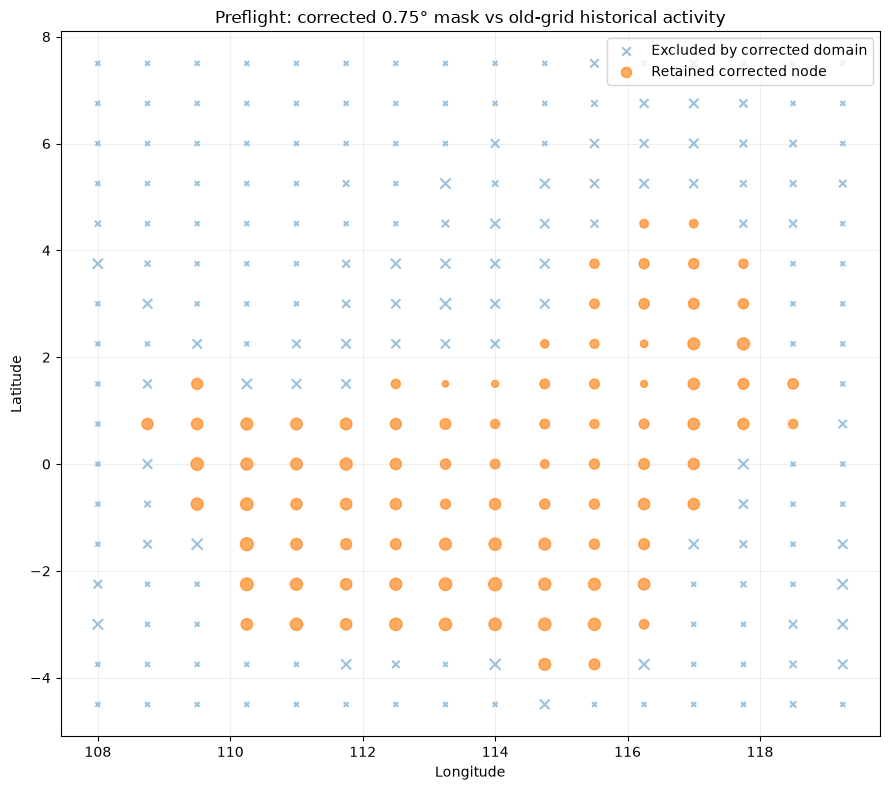

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset\figures\01_preflight_old_grid_mask_activity.png


In [114]:
# 6. Map retained/excluded 0.75° cells with historical activity size

if mask_compare is not None and {"grid_lat", "grid_lon", "keep_corrected"}.issubset(mask_compare.columns):
    plot_df = mask_compare.dropna(subset=["grid_lat", "grid_lon"]).copy()

    activity = (
        plot_df["total_fire_count"].to_numpy()
        if "total_fire_count" in plot_df.columns
        else np.ones(len(plot_df))
    )

    marker_size = 12 + 75 * np.log1p(activity) / max(1.0, np.log1p(activity).max())

    fig, ax = plt.subplots(figsize=(9, 8))

    kept = plot_df[plot_df["keep_corrected"].astype(bool)]
    dropped = plot_df[~plot_df["keep_corrected"].astype(bool)]

    kept_size = marker_size[plot_df["keep_corrected"].astype(bool).to_numpy()]
    dropped_size = marker_size[~plot_df["keep_corrected"].astype(bool).to_numpy()]

    ax.scatter(
        dropped["grid_lon"],
        dropped["grid_lat"],
        s=dropped_size,
        marker="x",
        alpha=0.45,
        label="Excluded by corrected domain",
    )

    ax.scatter(
        kept["grid_lon"],
        kept["grid_lat"],
        s=kept_size,
        alpha=0.65,
        label="Retained corrected node",
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Preflight: corrected 0.75° mask vs old-grid historical activity")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()

    path = FIGURES_DIR / "01_preflight_old_grid_mask_activity.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

# PART C — Optional non-blocking attention sanity check

Notebook 14 attention is averaged over August and saved by static edge. It can be inspected for concentration and distance dependence.

It **cannot** answer “does GAT attend to upwind neighbors?” because that requires edge-level attention for each day plus daily wind alignment.

In [115]:
# 7. Static GAT attention sanity check (non-blocking)

ATTENTION_PATH = NB14_RESULTS / "gat_attention_summary.csv"

if ATTENTION_PATH.exists():
    attention = pd.read_csv(ATTENTION_PATH)

    print("Top static GAT edges by mean August attention:")
    display(attention.head(15))

    if {"distance_km", "mean_august_attention"}.issubset(attention.columns):
        rank_corr = (
            attention["distance_km"].rank()
            .corr(attention["mean_august_attention"].rank())
        )
        print("Spearman-like rank correlation distance vs attention:", round(float(rank_corr), 4))

    print(
        "Do NOT interpret this table as an upwind-attention test. "
        "The saved attention is time-averaged and has no edge-day wind direction."
    )
else:
    print("Notebook 14 attention CSV not found; this does not block Notebook 17.")

Top static GAT edges by mean August attention:


,source_cell_id,target_cell_id,distance_km,mean_august_attention
0,Kalimantan_0.75_110.25,Kalimantan_1.50_109.50,117.928405,0.394334
1,Kalimantan_-2.25_110.25,Kalimantan_-3.00_110.25,83.396310,0.365016
2,Kalimantan_-2.25_110.25,Kalimantan_-3.00_111.00,117.877907,0.354974
3,Kalimantan_-3.00_116.25,Kalimantan_-3.75_115.50,117.837534,0.332505
4,Kalimantan_-2.25_114.00,Kalimantan_-1.50_114.75,117.908201,0.322606
5,Kalimantan_2.25_117.75,Kalimantan_1.50_118.50,117.908201,0.317977
6,Kalimantan_0.00_109.50,Kalimantan_0.75_108.75,117.938509,0.315027
7,Kalimantan_-2.25_113.25,Kalimantan_-1.50_112.50,117.908201,0.314898
8,Kalimantan_-3.00_115.50,Kalimantan_-3.00_116.25,83.282017,0.310606
9,Kalimantan_-3.00_115.50,Kalimantan_-2.25_116.25,117.877907,0.306819


Spearman-like rank correlation distance vs attention: 0.0232
Do NOT interpret this table as an upwind-attention test. The saved attention is time-averaged and has no edge-day wind direction.


# PART D — Raw FIRMS source

The authoritative fire source for this notebook is the Kalimantan **hourly** FIRMS folder.

In [116]:
# 8. Discover Kalimantan hourly FIRMS folder

DATASET_ROOT = None  # optional manual override


def has_firms_files(folder):
    return folder.exists() and folder.is_dir() and any(folder.glob("fires_*.csv"))


def is_kalimantan_path(path):
    return "kalimantan" in [str(p).lower() for p in Path(path).parts]


def find_kalimantan_firms_folder(dataset_root=None):
    search_roots = []

    if dataset_root is not None:
        search_roots.append(Path(dataset_root))

    search_roots.extend([
        PROJECT_ROOT,
        PROJECT_ROOT.parent,
        Path.home() / "Documents",
        Path.home() / "Downloads",
    ])

    roots = []
    seen = set()

    for root in search_roots:
        if not root.exists():
            continue
        key = str(root.resolve()).lower()
        if key not in seen:
            roots.append(root)
            seen.add(key)

    direct = []
    for root in roots:
        direct.extend([
            root / "data" / "raw" / "kalimantan" / "fire_firms" / "hourly",
            root / "data" / "kalimantan" / "fire_firms" / "hourly",
            root / "KARHUT_Data_Share" / "data" / "kalimantan" / "fire_firms" / "hourly",
        ])

    for candidate in direct:
        if is_kalimantan_path(candidate) and has_firms_files(candidate):
            return candidate

    matches = []
    for root in roots:
        try:
            for directory in root.rglob("fire_firms"):
                if not is_kalimantan_path(directory):
                    continue
                hourly = directory / "hourly"
                if has_firms_files(hourly):
                    matches.append(hourly)
        except (OSError, PermissionError):
            continue

    if matches:
        return sorted(matches, key=lambda p: len(str(p)))[0]

    return None


FIRE_FIRMS_DIR = find_kalimantan_firms_folder(DATASET_ROOT)

if FIRE_FIRMS_DIR is None:
    raise FileNotFoundError(
        "Could not find Kalimantan hourly FIRMS files. Set DATASET_ROOT manually."
    )

fire_files = sorted(FIRE_FIRMS_DIR.glob("fires_*.csv"))

print("FIRMS folder:", FIRE_FIRMS_DIR)
print("Files       :", len(fire_files))
print("First / last:", fire_files[0].name, "/", fire_files[-1].name)

FIRMS folder: c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly
Files       : 134
First / last: fires_2026-05-01.csv / fires_2026-09-11.csv


In [117]:
# 9. Load FIRMS through the last complete day

DATA_START = pd.Timestamp("2026-05-01")
LAST_COMPLETE_FIRE_DAY = pd.Timestamp("2026-09-10")
TRAIN_END = pd.Timestamp("2026-07-31")
VALIDATION_START = pd.Timestamp("2026-08-01")
VALIDATION_END = pd.Timestamp("2026-08-31")
TEST_START = pd.Timestamp("2026-09-01")

pattern = re.compile(r"fires_(\d{4}-\d{2}-\d{2})\.csv$")
frames = []

for path in fire_files:
    match = pattern.search(path.name)
    if not match:
        continue

    date = pd.Timestamp(match.group(1))

    if not (DATA_START <= date <= LAST_COMPLETE_FIRE_DAY):
        continue

    day = pd.read_csv(path)
    if day.empty:
        continue

    rename_map = {}
    if "latitude" in day.columns and "lat" not in day.columns:
        rename_map["latitude"] = "lat"
    if "longitude" in day.columns and "lon" not in day.columns:
        rename_map["longitude"] = "lon"
    day = day.rename(columns=rename_map)

    if not {"lat", "lon"}.issubset(day.columns):
        raise ValueError(f"Missing lat/lon in {path.name}")

    if "frp" not in day.columns:
        day["frp"] = np.nan

    day = day[["lat", "lon", "frp"]].copy()
    day["date"] = date
    frames.append(day)

fires_raw = pd.concat(frames, ignore_index=True)

for c in ["lat", "lon", "frp"]:
    fires_raw[c] = pd.to_numeric(fires_raw[c], errors="coerce")

fires_raw = fires_raw.dropna(subset=["lat", "lon"]).reset_index(drop=True)

print("Raw detections:", len(fires_raw))
print("Date range    :", fires_raw["date"].min().date(), "→", fires_raw["date"].max().date())
print("Train-period detections:", int((fires_raw["date"] <= TRAIN_END).sum()))

Raw detections: 141628
Date range    : 2026-05-01 → 2026-09-10
Train-period detections: 11101


# PART E — Rebuild Indonesian Kalimantan geometry

This uses the same main-Borneo ∩ Indonesia logic as the corrected domain notebook.

In [118]:
# 10. Natural Earth cache / download helper

NATURAL_EARTH = {
    "land": (
        "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip",
        "ne_10m_land",
    ),
    "countries": (
        "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip",
        "ne_10m_admin_0_countries",
    ),
    "admin1": (
        "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip",
        "ne_10m_admin_1_states_provinces",
    ),
    "lakes": (
        "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_lakes.zip",
        "ne_10m_lakes",
    ),
    "rivers": (
        "https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_rivers_lake_centerlines.zip",
        "ne_10m_rivers_lake_centerlines",
    ),
}


def download_ne(key):
    url, stem = NATURAL_EARTH[key]
    folder = NE_DIR / stem
    shp = folder / f"{stem}.shp"

    if shp.exists():
        return shp

    folder.mkdir(parents=True, exist_ok=True)
    zip_path = NE_DIR / f"{stem}.zip"

    if not zip_path.exists():
        print("Downloading:", url)
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        zip_path.write_bytes(response.content)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(folder)

    if not shp.exists():
        options = list(folder.glob("*.shp"))
        if not options:
            raise FileNotFoundError(f"No shapefile after extracting {zip_path}")
        shp = options[0]

    return shp


ne_paths = {k: download_ne(k) for k in NATURAL_EARTH}

In [119]:
# 11. Indonesian Kalimantan geometry

land = gpd.read_file(ne_paths["land"]).to_crs(4326)
countries = gpd.read_file(ne_paths["countries"]).to_crs(4326)
admin1 = gpd.read_file(ne_paths["admin1"]).to_crs(4326)
lakes = gpd.read_file(ne_paths["lakes"]).to_crs(4326)
rivers = gpd.read_file(ne_paths["rivers"]).to_crs(4326)

land_parts = land[["geometry"]].explode(index_parts=False).reset_index(drop=True)
borneo_seed = Point(114.0, 0.5)
borneo_candidates = land_parts[land_parts.geometry.contains(borneo_seed)]

if borneo_candidates.empty:
    raise RuntimeError("Could not identify Borneo main polygon.")

borneo_geom = borneo_candidates.iloc[0].geometry

country_mask = pd.Series(False, index=countries.index)
for field, value in [
    ("ADM0_A3", "IDN"),
    ("SOV_A3", "IDN"),
    ("ISO_A2", "ID"),
]:
    if field in countries.columns:
        country_mask |= countries[field].astype(str).eq(value)

if "ADMIN" in countries.columns:
    country_mask |= countries["ADMIN"].astype(str).str.lower().eq("indonesia")

indonesia = countries[country_mask].copy()

if indonesia.empty:
    raise RuntimeError("Could not identify Indonesia polygon.")

indonesia_geom = indonesia.geometry.union_all()
kalimantan_geom = indonesia_geom.intersection(borneo_geom)

kalimantan_gdf = gpd.GeoDataFrame(
    {"name": ["Indonesian Kalimantan"]},
    geometry=[kalimantan_geom],
    crs=4326,
)

print("Indonesian Kalimantan bounds:", kalimantan_geom.bounds)

Indonesian Kalimantan bounds: (108.85547936300003, -4.184177341999941, 119.01172936300009, 4.396787008000018)


In [120]:
# 12. Filter FIRMS points to Indonesian Kalimantan

fire_points = gpd.GeoDataFrame(
    fires_raw.copy(),
    geometry=gpd.points_from_xy(fires_raw["lon"], fires_raw["lat"]),
    crs=4326,
)

inside = fire_points.geometry.intersects(kalimantan_geom)
fires_kalimantan = fire_points.loc[inside].copy().reset_index(drop=True)

print("Raw FIRMS       :", len(fire_points))
print("Inside Kalimantan:", len(fires_kalimantan))
print("Retention %     :", round(100 * len(fires_kalimantan) / len(fire_points), 2))

Raw FIRMS       : 141628
Inside Kalimantan: 135017
Retention %     : 95.33


# PART F — Preflight Gate B: train-only regional study-area lock

**Critical rule:** candidate ranking below uses only May–July FIRMS data.

August and September are not used to choose the regional bounding box.

In [121]:
# 13. Train-only discovery density

DISCOVERY_STEP = 0.25
ANCHOR_LON = 108.0
ANCHOR_LAT = -4.5

selection_fires = fires_kalimantan[
    (fires_kalimantan["date"] >= DATA_START)
    & (fires_kalimantan["date"] <= TRAIN_END)
].copy()

if selection_fires.empty:
    raise ValueError("No May–July FIRMS detections available for region selection.")

selection_fires["disc_col"] = np.floor(
    (selection_fires["lon"] - ANCHOR_LON) / DISCOVERY_STEP
).astype(int)

selection_fires["disc_row"] = np.floor(
    (selection_fires["lat"] - ANCHOR_LAT) / DISCOVERY_STEP
).astype(int)

density = (
    selection_fires
    .groupby(["disc_row", "disc_col"], as_index=False)
    .size()
    .rename(columns={"size": "detections"})
)

row_min = int(density["disc_row"].min())
row_max = int(density["disc_row"].max())
col_min = int(density["disc_col"].min())
col_max = int(density["disc_col"].max())

matrix = np.zeros(
    (row_max - row_min + 1, col_max - col_min + 1),
    dtype=float,
)

for row in density.itertuples(index=False):
    matrix[int(row.disc_row - row_min), int(row.disc_col - col_min)] = row.detections


def box_sum_2d(x, radius=2):
    padded = np.pad(x, radius, mode="constant", constant_values=0)
    output = np.zeros_like(x, dtype=float)
    width = 2 * radius + 1
    for dr in range(width):
        for dc in range(width):
            output += padded[dr:dr+x.shape[0], dc:dc+x.shape[1]]
    return output


smoothed = box_sum_2d(matrix, radius=2)
print("Selection FIRMS rows:", len(selection_fires))
print("Peak train-only 5x5 density:", int(smoothed.max()))

Selection FIRMS rows: 9170
Peak train-only 5x5 density: 1301


In [122]:
# 14. Build separated 3°×3° candidate windows from training only

N_CANDIDATES = 5
MIN_CENTER_SEPARATION_DEG = 2.0
WINDOW_WIDTH_DEG = 3.0
HALF_WIDTH = WINDOW_WIDTH_DEG / 2.0

candidate_centers = []

for flat_index in np.argsort(smoothed.ravel())[::-1]:
    mr, mc = np.unravel_index(flat_index, smoothed.shape)
    disc_row = mr + row_min
    disc_col = mc + col_min

    center_lat = ANCHOR_LAT + (disc_row + 0.5) * DISCOVERY_STEP
    center_lon = ANCHOR_LON + (disc_col + 0.5) * DISCOVERY_STEP
    center = Point(center_lon, center_lat)

    if not center.within(kalimantan_geom):
        continue

    if any(
        math.hypot(
            center_lon - prev["center_lon"],
            center_lat - prev["center_lat"],
        ) < MIN_CENTER_SEPARATION_DEG
        for prev in candidate_centers
    ):
        continue

    candidate_centers.append({
        "center_lon": center_lon,
        "center_lat": center_lat,
        "train_peak_density_score": float(smoothed[mr, mc]),
    })

    if len(candidate_centers) >= N_CANDIDATES:
        break

train_candidates = pd.DataFrame(candidate_centers)
train_candidates["candidate_id"] = [f"T{i+1}" for i in range(len(train_candidates))]
train_candidates["west"] = train_candidates["center_lon"] - HALF_WIDTH
train_candidates["east"] = train_candidates["center_lon"] + HALF_WIDTH
train_candidates["south"] = train_candidates["center_lat"] - HALF_WIDTH
train_candidates["north"] = train_candidates["center_lat"] + HALF_WIDTH

display(train_candidates)

,center_lon,center_lat,train_peak_density_score,candidate_id,west,east,south,north
0,109.875,0.125,1301.0,T1,108.375,111.375,-1.375,1.625
1,115.125,-2.625,1141.0,T2,113.625,116.625,-4.125,-1.125
2,110.625,-1.875,846.0,T3,109.125,112.125,-3.375,-0.375
3,117.375,1.125,644.0,T4,115.875,118.875,-0.375,2.625
4,111.875,0.125,325.0,T5,110.375,113.375,-1.375,1.625


In [123]:
# 15. Fine-grid candidate statistics restricted to training period

SELECTION_DATES = pd.date_range(DATA_START, TRAIN_END, freq="D")


def aligned_index_range(low, high, anchor, step):
    start = math.floor((low - anchor) / step)
    end = math.floor((high - anchor) / step)
    return range(start, end + 1)


def candidate_center_cells(bbox_tuple, step=0.25):
    west, south, east, north = bbox_tuple
    rows = []

    for col_idx in aligned_index_range(west, east, ANCHOR_LON, step):
        cell_west = ANCHOR_LON + col_idx * step
        center_lon = cell_west + step / 2
        if not (west <= center_lon <= east):
            continue

        for row_idx in aligned_index_range(south, north, ANCHOR_LAT, step):
            cell_south = ANCHOR_LAT + row_idx * step
            center_lat = cell_south + step / 2
            if not (south <= center_lat <= north):
                continue

            center = Point(center_lon, center_lat)
            if center.within(kalimantan_geom):
                rows.append({
                    "row_idx": row_idx,
                    "col_idx": col_idx,
                    "center_lat": center_lat,
                    "center_lon": center_lon,
                    "cell_id": f"g{step:.2f}_{row_idx}_{col_idx}",
                })

    return pd.DataFrame(rows)


def training_candidate_stats(bbox_tuple, step=0.25):
    valid_cells = candidate_center_cells(bbox_tuple, step)

    if valid_cells.empty:
        return {
            "valid_cells": 0,
            "active_cells": 0,
            "detections": 0,
            "active_days": 0,
            "emerging3": 0,
            "persistent3": 0,
        }

    west, south, east, north = bbox_tuple

    regional = selection_fires[
        selection_fires["lon"].between(west, east, inclusive="both")
        & selection_fires["lat"].between(south, north, inclusive="both")
    ].copy()

    regional["col_idx"] = np.floor(
        (regional["lon"] - ANCHOR_LON) / step
    ).astype(int)
    regional["row_idx"] = np.floor(
        (regional["lat"] - ANCHOR_LAT) / step
    ).astype(int)

    regional = regional.merge(
        valid_cells[["row_idx", "col_idx", "cell_id"]],
        on=["row_idx", "col_idx"],
        how="inner",
    )

    active_daily = (
        regional
        .groupby(["date", "cell_id"], as_index=False)
        .size()
        .rename(columns={"size": "fire_count"})
    )

    full_index = pd.MultiIndex.from_product(
        [SELECTION_DATES, valid_cells["cell_id"]],
        names=["date", "cell_id"],
    )

    panel = (
        active_daily
        .set_index(["date", "cell_id"])
        .reindex(full_index)
        .reset_index()
    )

    panel["fire_count"] = panel["fire_count"].fillna(0)
    panel["fire_active"] = panel["fire_count"].gt(0).astype(int)
    panel = panel.sort_values(["cell_id", "date"]).reset_index(drop=True)

    panel["recent3_incl_t"] = (
        panel.groupby("cell_id")["fire_active"]
        .transform(lambda s: s.rolling(3, min_periods=3).sum())
    )
    panel["target_t1"] = panel.groupby("cell_id")["fire_active"].shift(-1)

    eligible = panel[
        panel["recent3_incl_t"].notna()
        & panel["target_t1"].notna()
    ].copy()

    emerging = eligible["target_t1"].eq(1) & eligible["recent3_incl_t"].eq(0)
    persistent = eligible["target_t1"].eq(1) & eligible["recent3_incl_t"].gt(0)

    return {
        "valid_cells": int(len(valid_cells)),
        "active_cells": int(regional["cell_id"].nunique()),
        "detections": int(len(regional)),
        "active_days": int(regional["date"].nunique()),
        "emerging3": int(emerging.sum()),
        "persistent3": int(persistent.sum()),
    }


rows = []
for row in train_candidates.itertuples(index=False):
    bbox_tuple = (row.west, row.south, row.east, row.north)
    stats = training_candidate_stats(bbox_tuple, 0.25)
    rows.append({
        **row._asdict(),
        **stats,
    })

train_candidate_stats = pd.DataFrame(rows)

# Same ranking logic as Notebook 16, but TRAINING-ONLY.
train_candidate_ranking = (
    train_candidate_stats
    .sort_values(
        [
            "active_days",
            "active_cells",
            "detections",
            "train_peak_density_score",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

train_candidate_ranking["selection_rank"] = (
    np.arange(len(train_candidate_ranking)) + 1
)

display(
    train_candidate_ranking[
        [
            "selection_rank",
            "candidate_id",
            "center_lon",
            "center_lat",
            "active_days",
            "active_cells",
            "detections",
            "train_peak_density_score",
            "emerging3",
            "persistent3",
            "west",
            "south",
            "east",
            "north",
        ]
    ]
)

,selection_rank,candidate_id,center_lon,center_lat,active_days,active_cells,detections,train_peak_density_score,emerging3,persistent3,west,south,east,north
0,1,T2,115.125,-2.625,82,95,2293,1141.0,261,497,113.625,-4.125,116.625,-1.125
1,2,T4,117.375,1.125,76,74,1209,644.0,282,275,115.875,-0.375,118.875,2.625
2,3,T1,109.875,0.125,63,92,2561,1301.0,364,361,108.375,-1.375,111.375,1.625
3,4,T3,110.625,-1.875,58,92,1743,846.0,309,378,109.125,-3.375,112.125,-0.375
4,5,T5,111.875,0.125,57,98,1378,325.0,287,283,110.375,-1.375,113.375,1.625


## 16. Lock the final regional domain

The selected region below is the only regional bounding box used by the rest of Notebook 17.

Notebook 16's full-period C1 is shown only as a comparison if its metadata exists; it does not control this selection.

In [124]:
# 16. Train-only region lock

locked = train_candidate_ranking.iloc[0].copy()

LOCKED_REGION_ID = str(locked["candidate_id"])
LOCKED_BBOX = (
    float(locked["west"]),
    float(locked["south"]),
    float(locked["east"]),
    float(locked["north"]),
)

print("TRAIN-ONLY LOCKED REGION")
print("Candidate   :", LOCKED_REGION_ID)
print("BBox        :", LOCKED_BBOX)
print("Train detections:", int(locked["detections"]))
print("Train active days:", int(locked["active_days"]))
print("Train 0.25° Emerging3:", int(locked["emerging3"]))
print("Train valid center cells:", int(locked["valid_cells"]))

nb16_metadata_path = NB16_RESULTS / "exports" / "chosen_region_metadata.json"

if nb16_metadata_path.exists():
    old_meta = json.loads(nb16_metadata_path.read_text(encoding="utf-8"))
    old_bbox = old_meta.get("bbox_wgs84", {})
    old_bbox_tuple = (
        old_bbox.get("west"),
        old_bbox.get("south"),
        old_bbox.get("east"),
        old_bbox.get("north"),
    )

    print("\nNotebook 16 exploratory full-period region:")
    print("Candidate:", old_meta.get("candidate_id"))
    print("BBox     :", old_bbox_tuple)
    print("Same bbox as train-only lock:", old_bbox_tuple == LOCKED_BBOX)

lock_metadata = {
    "selection_data_start": str(DATA_START.date()),
    "selection_data_end": str(TRAIN_END.date()),
    "selection_uses_august": False,
    "selection_uses_september": False,
    "candidate_id": LOCKED_REGION_ID,
    "bbox_wgs84": {
        "west": LOCKED_BBOX[0],
        "south": LOCKED_BBOX[1],
        "east": LOCKED_BBOX[2],
        "north": LOCKED_BBOX[3],
    },
    "selection_rule": [
        "train_emerging3 descending",
        "train_active_days descending",
        "train_active_cells descending",
        "train_detections descending",
    ],
}

lock_path = EXPORT_DIR / "regional_domain_lock_train_only.json"
lock_path.write_text(json.dumps(lock_metadata, indent=2), encoding="utf-8")
print("\nSaved lock:", lock_path)

TRAIN-ONLY LOCKED REGION
Candidate   : T2
BBox        : (113.625, -4.125, 116.625, -1.125)
Train detections: 2293
Train active days: 82
Train 0.25° Emerging3: 261
Train valid center cells: 123

Notebook 16 exploratory full-period region:
Candidate: C1
BBox     : (112.375, -3.375, 115.375, -0.375)
Same bbox as train-only lock: False

Saved lock: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset\exports\regional_domain_lock_train_only.json


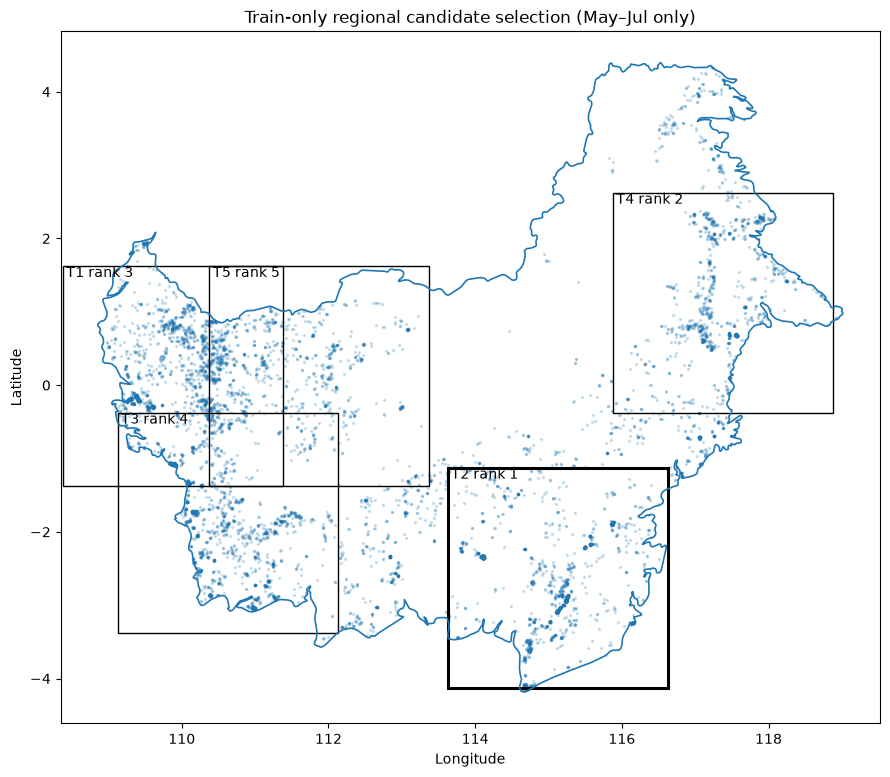

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset\figures\02_train_only_region_candidates.png


In [125]:
# 17. Candidate overview map — training-only

fig, ax = plt.subplots(figsize=(9, 8))

kalimantan_gdf.boundary.plot(ax=ax, linewidth=1.2)

sample = selection_fires.sample(
    n=min(20000, len(selection_fires)),
    random_state=RANDOM_STATE,
)
sample.plot(ax=ax, markersize=2, alpha=0.18)

for row in train_candidate_ranking.itertuples(index=False):
    rect = plt.Rectangle(
        (row.west, row.south),
        row.east - row.west,
        row.north - row.south,
        fill=False,
        linewidth=2.2 if row.selection_rank == 1 else 1.0,
    )
    ax.add_patch(rect)
    ax.text(row.west + 0.05, row.north - 0.15, f"{row.candidate_id} rank {row.selection_rank}")

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Train-only regional candidate selection (May–Jul only)")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()

path = FIGURES_DIR / "02_train_only_region_candidates.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART G — Build final 0.25° regional node grid

Node inclusion is based on physical geography, not historical fire frequency.

Default geometric rule:

```text
keep if Indonesian-Kalimantan land overlap >= 20%
OR cell center is inside Indonesian Kalimantan
```

The 20% threshold is fixed before model evaluation and is not tuned for performance.

In [126]:
# 18. Construct all 0.25° cells whose centers lie inside the locked regional window

GRID_STEP = 0.25
DEFAULT_LAND_OVERLAP_THRESHOLD = 0.20

west, south, east, north = LOCKED_BBOX
node_rows = []

for col_idx in aligned_index_range(west, east, ANCHOR_LON, GRID_STEP):
    cell_west = ANCHOR_LON + col_idx * GRID_STEP
    center_lon = cell_west + GRID_STEP / 2

    if not (west <= center_lon <= east):
        continue

    for row_idx in aligned_index_range(south, north, ANCHOR_LAT, GRID_STEP):
        cell_south = ANCHOR_LAT + row_idx * GRID_STEP
        center_lat = cell_south + GRID_STEP / 2

        if not (south <= center_lat <= north):
            continue

        geom = box(
            cell_west,
            cell_south,
            cell_west + GRID_STEP,
            cell_south + GRID_STEP,
        )

        node_rows.append({
            "row_idx": row_idx,
            "col_idx": col_idx,
            "cell_id": f"regional025_{row_idx}_{col_idx}",
            "grid_lat": center_lat,
            "grid_lon": center_lon,
            "geometry": geom,
        })

regional_grid = gpd.GeoDataFrame(node_rows, geometry="geometry", crs=4326)

if regional_grid.empty:
    raise ValueError("Locked region produced an empty 0.25° grid.")

print("Rectangular center-selected cells:", len(regional_grid))

Rectangular center-selected cells: 169


In [127]:
# 19. Equal-area Indonesian-Kalimantan overlap

regional_equal = regional_grid.to_crs(6933)
kalimantan_equal = kalimantan_gdf.to_crs(6933).geometry.iloc[0]

regional_grid["cell_area_m2"] = regional_equal.geometry.area.to_numpy()
regional_grid["kalimantan_land_area_m2"] = (
    regional_equal.geometry.intersection(kalimantan_equal).area.to_numpy()
)
regional_grid["land_fraction"] = (
    regional_grid["kalimantan_land_area_m2"]
    / regional_grid["cell_area_m2"]
).clip(0.0, 1.0)

centers = gpd.GeoSeries(
    gpd.points_from_xy(regional_grid["grid_lon"], regional_grid["grid_lat"]),
    crs=4326,
)
regional_grid["center_inside_kalimantan"] = centers.intersects(kalimantan_geom).to_numpy()

regional_grid["keep_land"] = (
    regional_grid["land_fraction"].ge(DEFAULT_LAND_OVERLAP_THRESHOLD)
    | regional_grid["center_inside_kalimantan"]
)

threshold_rows = []
for threshold in [0.05, 0.10, 0.20, 0.30, 0.50]:
    keep = regional_grid["land_fraction"].ge(threshold) | regional_grid["center_inside_kalimantan"]
    threshold_rows.append({
        "land_overlap_threshold": threshold,
        "kept_cells": int(keep.sum()),
        "excluded_cells": int((~keep).sum()),
    })

regional_land_threshold_sensitivity = pd.DataFrame(threshold_rows)
display(regional_land_threshold_sensitivity)

,land_overlap_threshold,kept_cells,excluded_cells
0,0.05,136,33
1,0.10,135,34
2,0.20,133,36
3,0.30,131,38
4,0.50,125,44


# PART H — High-resolution water screen with JRC Global Surface Water

The JRC occurrence product stores the percentage of observations in which a pixel was classified as water.

To avoid deleting seasonal wetlands / peat areas too aggressively, the **hard exclusion rule is deliberately conservative**:

```text
water90_fraction >= 0.80
```

where `water90_fraction` is the fraction of raster pixels in the grid cell whose long-term water occurrence is at least 90%.

This targets cells that are overwhelmingly near-permanent water. Lower-occurrence water metrics are saved for later analysis but do not remove nodes.

If JRC download/rasterio is unavailable, the notebook keeps the Natural-Earth land mask and clearly marks the high-resolution water audit as incomplete.

In [128]:
# 20. Determine required JRC 10°×10° occurrence tiles

JRC_VERSION = "v1_4_2021"
JRC_STATISTIC = "occurrence"
JRC_WATER_OCCURRENCE_THRESHOLD = 90
JRC_WATER_DOMINANT_CELL_THRESHOLD = 0.80


def coord_token(value, positive_suffix, negative_suffix):
    value = int(value)
    if value < 0:
        return f"{abs(value)}{negative_suffix}"
    return f"{abs(value)}{positive_suffix}"


def required_gsw_tiles(bbox_tuple):
    west, south, east, north = bbox_tuple

    lon_starts = range(
        math.floor(west / 10) * 10,
        math.floor((east - 1e-9) / 10) * 10 + 1,
        10,
    )

    lat_bottoms = range(
        math.floor(south / 10) * 10,
        math.floor((north - 1e-9) / 10) * 10 + 1,
        10,
    )

    tiles = []
    for lon0 in lon_starts:
        for lat0 in lat_bottoms:
            lat_top = lat0 + 10
            tile_id = (
                f"{coord_token(lon0, 'E', 'W')}_"
                f"{coord_token(lat_top, 'N', 'S')}"
            )
            filename = f"occurrence_{tile_id}{JRC_VERSION}.tif"
            url = (
                "https://storage.googleapis.com/global-surface-water/"
                f"downloads2021/occurrence/{filename}"
            )
            tiles.append({
                "tile_id": tile_id,
                "filename": filename,
                "url": url,
                "west": lon0,
                "south": lat0,
                "east": lon0 + 10,
                "north": lat0 + 10,
            })

    return pd.DataFrame(tiles)


jrc_tiles = required_gsw_tiles(LOCKED_BBOX)
display(jrc_tiles)

,tile_id,filename,url,west,south,east,north
0,110E_0N,occurrence_110E_0Nv1_4_2021.tif,https://storage.googleapis.com/global-surface-...,110,-10,120,0


In [129]:
# 21. Download/cache JRC occurrence tiles

JRC_AVAILABLE = RASTERIO_AVAILABLE
jrc_local_paths = []

if not RASTERIO_AVAILABLE:
    print(
        "rasterio is not installed. High-resolution JRC water screening will be skipped.\n"
        "Install with: python -m pip install rasterio"
    )
else:
    for row in jrc_tiles.itertuples(index=False):
        local_path = JRC_DIR / row.filename

        if not local_path.exists():
            print("Downloading JRC:", row.url)
            try:
                response = requests.get(row.url, timeout=180)
                response.raise_for_status()
                local_path.write_bytes(response.content)
            except Exception as exc:
                print("JRC download failed:", exc)
                JRC_AVAILABLE = False
                break

        jrc_local_paths.append(local_path)

    if JRC_AVAILABLE:
        print("JRC tiles ready:")
        for path in jrc_local_paths:
            print("-", path)

JRC tiles ready:
- c:\Users\Asus\Documents\skripsi-karhut\data\external\jrc_gsw_v1_4_2021\occurrence_110E_0Nv1_4_2021.tif


In [130]:
# 22. Compute JRC water occurrence statistics for every 0.25° cell

regional_grid["jrc_mean_water_occurrence"] = np.nan
regional_grid["jrc_water_any_fraction"] = np.nan
regional_grid["jrc_water50_fraction"] = np.nan
regional_grid["jrc_water90_fraction"] = np.nan

if JRC_AVAILABLE:
    datasets = [rasterio.open(path) for path in jrc_local_paths]

    try:
        for idx, cell in regional_grid.iterrows():
            minx, miny, maxx, maxy = cell.geometry.bounds
            collected = []

            for ds in datasets:
                ds_bounds = ds.bounds

                intersects = not (
                    maxx <= ds_bounds.left
                    or minx >= ds_bounds.right
                    or maxy <= ds_bounds.bottom
                    or miny >= ds_bounds.top
                )

                if not intersects:
                    continue

                clip_minx = max(minx, ds_bounds.left)
                clip_miny = max(miny, ds_bounds.bottom)
                clip_maxx = min(maxx, ds_bounds.right)
                clip_maxy = min(maxy, ds_bounds.top)

                window = raster_window_from_bounds(
                    clip_minx,
                    clip_miny,
                    clip_maxx,
                    clip_maxy,
                    transform=ds.transform,
                )

                arr = ds.read(1, window=window)
                valid = arr[(arr >= 0) & (arr <= 100)]

                if valid.size:
                    collected.append(valid.astype(np.float32))

            if collected:
                values = np.concatenate(collected)
                regional_grid.loc[idx, "jrc_mean_water_occurrence"] = float(values.mean())
                regional_grid.loc[idx, "jrc_water_any_fraction"] = float((values > 0).mean())
                regional_grid.loc[idx, "jrc_water50_fraction"] = float((values >= 50).mean())
                regional_grid.loc[idx, "jrc_water90_fraction"] = float((values >= 90).mean())

    finally:
        for ds in datasets:
            ds.close()

    print("JRC screening complete.")
else:
    print("JRC screening unavailable; water metrics remain NaN.")

JRC screening complete.


In [131]:
# 23. Final physical-node mask

if JRC_AVAILABLE:
    regional_grid["water_dominant_permanent"] = (
        regional_grid["jrc_water90_fraction"].fillna(0)
        >= JRC_WATER_DOMINANT_CELL_THRESHOLD
    )
else:
    regional_grid["water_dominant_permanent"] = False

regional_grid["keep_final"] = (
    regional_grid["keep_land"]
    & ~regional_grid["water_dominant_permanent"]
)

node_mask_summary = pd.DataFrame([
    {
        "rectangular_cells": len(regional_grid),
        "keep_land_cells": int(regional_grid["keep_land"].sum()),
        "permanent_water_dominant_cells": int(regional_grid["water_dominant_permanent"].sum()),
        "final_nodes": int(regional_grid["keep_final"].sum()),
        "jrc_available": bool(JRC_AVAILABLE),
        "land_overlap_threshold": DEFAULT_LAND_OVERLAP_THRESHOLD,
        "jrc_pixel_occurrence_threshold": JRC_WATER_OCCURRENCE_THRESHOLD,
        "jrc_cell_water_fraction_threshold": JRC_WATER_DOMINANT_CELL_THRESHOLD,
    }
])

display(node_mask_summary)

final_nodes = regional_grid[regional_grid["keep_final"]].copy().reset_index(drop=True)
final_nodes["node_index"] = np.arange(len(final_nodes))

if final_nodes.empty:
    raise ValueError("Physical mask removed every regional node.")

,rectangular_cells,keep_land_cells,permanent_water_dominant_cells,final_nodes,jrc_available,land_overlap_threshold,jrc_pixel_occurrence_threshold,jrc_cell_water_fraction_threshold
0,169,133,25,133,True,0.2,90,0.8


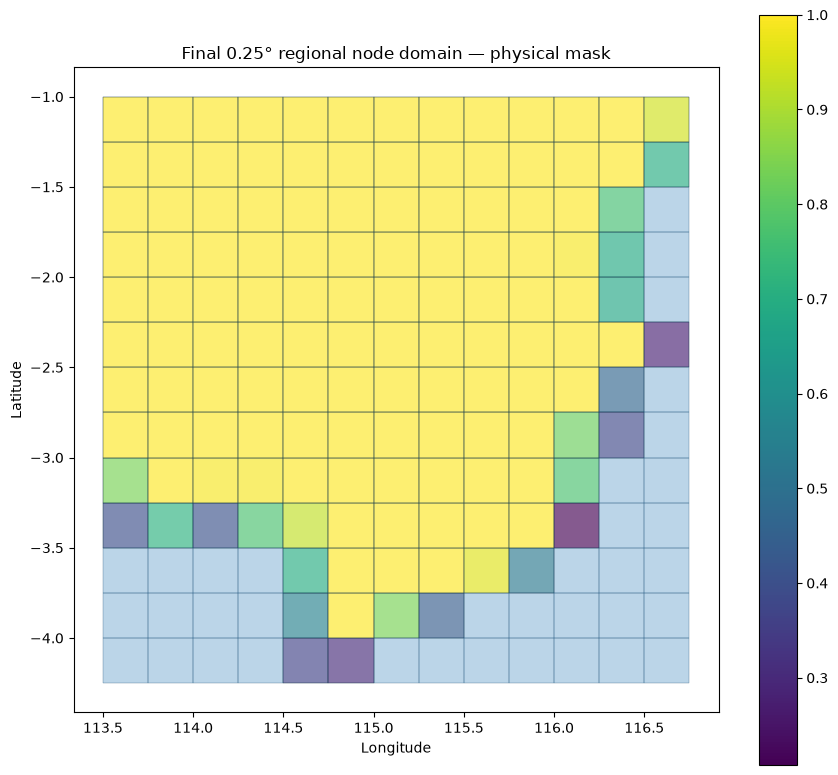

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset\figures\03_final_regional_025_nodes.png


In [132]:
# 24. Regional node map

fig, ax = plt.subplots(figsize=(9, 8))

regional_grid.boundary.plot(ax=ax, linewidth=0.25, alpha=0.45)

removed = regional_grid[~regional_grid["keep_final"]]
kept = regional_grid[regional_grid["keep_final"]]

if len(removed):
    removed.plot(ax=ax, alpha=0.30, edgecolor="black", linewidth=0.3, label="Excluded")

kept.plot(
    ax=ax,
    column="land_fraction",
    legend=True,
    alpha=0.65,
    edgecolor="black",
    linewidth=0.35,
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Final 0.25° regional node domain — physical mask")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()

path = FIGURES_DIR / "03_final_regional_025_nodes.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART I — Aggregate raw FIRMS into the locked 0.25° node grid

In [133]:
# 25. Assign FIRMS detections by deterministic aligned-grid indices

fires = fires_kalimantan.copy()

fires["col_idx"] = np.floor(
    (fires["lon"] - ANCHOR_LON) / GRID_STEP
).astype(int)

fires["row_idx"] = np.floor(
    (fires["lat"] - ANCHOR_LAT) / GRID_STEP
).astype(int)

node_lookup = final_nodes[["row_idx", "col_idx", "cell_id"]].copy()

regional_fires = fires.merge(
    node_lookup,
    on=["row_idx", "col_idx"],
    how="inner",
    validate="many_to_one",
)

print("All corrected-Kalimantan detections:", len(fires))
print("Detections in final regional nodes  :", len(regional_fires))
print("Regional active days                :", regional_fires["date"].nunique())
print("Regional active nodes               :", regional_fires["cell_id"].nunique(), "/", len(final_nodes))

All corrected-Kalimantan detections: 135017
Detections in final regional nodes  : 40911
Regional active days                : 122
Regional active nodes               : 128 / 133


In [134]:
# 26. Aggregate FIRMS to cell-day and build complete panel

active_daily = (
    regional_fires
    .groupby(["date", "cell_id"], as_index=False)
    .agg(
        fire_count=("frp", "size"),
        frp_sum=("frp", "sum"),
    )
)

ALL_COMPLETE_DATES = pd.date_range(
    DATA_START,
    LAST_COMPLETE_FIRE_DAY,
    freq="D",
)

full_index = pd.MultiIndex.from_product(
    [ALL_COMPLETE_DATES, final_nodes["cell_id"]],
    names=["date", "cell_id"],
)

fire_panel = (
    active_daily
    .set_index(["date", "cell_id"])
    .reindex(full_index)
    .reset_index()
)

fire_panel[["fire_count", "frp_sum"]] = (
    fire_panel[["fire_count", "frp_sum"]].fillna(0)
)

fire_panel["fire_active"] = fire_panel["fire_count"].gt(0).astype(int)

fire_panel = fire_panel.merge(
    final_nodes[
        [
            "cell_id",
            "node_index",
            "grid_lat",
            "grid_lon",
            "land_fraction",
            "jrc_mean_water_occurrence",
            "jrc_water_any_fraction",
            "jrc_water50_fraction",
            "jrc_water90_fraction",
        ]
    ],
    on="cell_id",
    how="left",
    validate="many_to_one",
)

fire_panel = fire_panel.sort_values(["cell_id", "date"]).reset_index(drop=True)

print("Complete cell-day panel:", fire_panel.shape)
print("Observed active cell-days:", int(fire_panel["fire_active"].sum()))

Complete cell-day panel: (17689, 13)
Observed active cell-days: 3725


# PART J — Rebuild temporal fire features and Emerging labels

Feature timing matches the previous benchmark:

```text
fire features: t-1 or earlier
weather: day t
label: fire-active at t+1
```

The current day's `fire_active(t)` is preserved in the dataset for diagnostics but is **not** part of the strict 20-feature benchmark set.

In [135]:
# 27. Fire-history benchmark features

for source_col in ["fire_count", "frp_sum"]:
    for lag in [1, 3, 7]:
        fire_panel[f"{source_col}_lag{lag}"] = (
            fire_panel.groupby("cell_id")[source_col].shift(lag)
        )

shifted_fire_count = fire_panel.groupby("cell_id")["fire_count"].shift(1)
shifted_frp_sum = fire_panel.groupby("cell_id")["frp_sum"].shift(1)

for window in [3, 7]:
    fire_panel[f"fire_count_roll{window}"] = (
        shifted_fire_count
        .groupby(fire_panel["cell_id"])
        .transform(lambda s: s.rolling(window, min_periods=window).sum())
    )

    fire_panel[f"frp_sum_roll{window}"] = (
        shifted_frp_sum
        .groupby(fire_panel["cell_id"])
        .transform(lambda s: s.rolling(window, min_periods=window).sum())
    )

fire_history_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

In [136]:
# 28. Next-day target + 3d / 7d event definitions

fire_panel["target_fire_active_t1"] = (
    fire_panel.groupby("cell_id")["fire_active"].shift(-1)
)

for window in [3, 7]:
    fire_panel[f"active_days_prev{window}_incl_t"] = (
        fire_panel.groupby("cell_id")["fire_active"]
        .transform(lambda s: s.rolling(window, min_periods=window).sum())
    )

    event_col = f"event_type_{window}d"
    recent_col = f"active_days_prev{window}_incl_t"

    fire_panel[event_col] = "Negative"

    persistent_mask = (
        fire_panel["target_fire_active_t1"].eq(1)
        & fire_panel[recent_col].gt(0)
    )

    emerging_mask = (
        fire_panel["target_fire_active_t1"].eq(1)
        & fire_panel[recent_col].eq(0)
    )

    fire_panel.loc[persistent_mask, event_col] = "Persistent"
    fire_panel.loc[emerging_mask, event_col] = "Emerging"

# PART K — ERA5 0.25° weather reconstruction

The old project weather was requested on a 1.25° point grid. For this regional 0.25° experiment, Notebook 17 requests **ERA5** directly at each regional node center.

The request uses:

- `models=era5`
- `cell_selection=nearest`
- `elevation=nan`
- UTC/GMT timestamps

This avoids Open-Meteo's default terrain-based land-cell selection from silently moving coastal requests to a different land grid cell.

The resulting source coordinates are stored and audited for duplicates / mapping distance.

In [137]:
# 29. Weather request configuration

WEATHER_HOURLY_VARIABLES = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "boundary_layer_height",
    "vapour_pressure_deficit",
    "wind_speed_10m",
    "wind_direction_10m",
]

WEATHER_DAILY_PATH = (
    REGIONAL_INTERMEDIATE
    / "weather_era5_daily_025.csv"
)

WEATHER_MAPPING_PATH = (
    REGIONAL_INTERMEDIATE
    / "weather_era5_mapping_025.csv"
)

OPEN_METEO_ARCHIVE_URL = (
    "https://archive-api.open-meteo.com/v1/archive"
)

# Smaller batch = safer for historical API
WEATHER_BATCH_SIZE = 5

MAX_RETRIES = 4

print(
    "Weather nodes to request:",
    len(final_nodes),
)

print(
    "Batch size:",
    WEATHER_BATCH_SIZE,
)

print(
    "Expected batches:",
    math.ceil(
        len(final_nodes)
        / WEATHER_BATCH_SIZE
    ),
)

Weather nodes to request: 133
Batch size: 5
Expected batches: 27


In [138]:
# 30. Robust Open-Meteo ERA5 batch fetch helper

def request_weather_batch(
    batch_df,
    batch_id,
):

    batch_cache = (
        WEATHER_BATCH_DIR
        / f"era5_batch_{batch_id:03d}.csv"
    )

    mapping_cache = (
        WEATHER_BATCH_DIR
        / f"era5_batch_{batch_id:03d}_mapping.csv"
    )

    # --------------------------------------------------------
    # Load cache if BOTH files already exist
    # --------------------------------------------------------

    if (
        batch_cache.exists()
        and mapping_cache.exists()
    ):

        print(
            f"  Batch {batch_id}: loading cache"
        )

        hourly_cached = pd.read_csv(
            batch_cache,
            parse_dates=["time_utc"],
        )

        mapping_cached = pd.read_csv(
            mapping_cache
        )

        return (
            hourly_cached,
            mapping_cached,
        )

    # --------------------------------------------------------
    # Coordinate lists
    # --------------------------------------------------------

    latitudes = (
        batch_df["grid_lat"]
        .astype(float)
        .tolist()
    )

    longitudes = (
        batch_df["grid_lon"]
        .astype(float)
        .tolist()
    )

    n_locations = len(
        batch_df
    )

    if (
        len(latitudes)
        != len(longitudes)
    ):
        raise ValueError(
            "Latitude / longitude count mismatch."
        )

    # --------------------------------------------------------
    # IMPORTANT:
    # one elevation value for every requested coordinate
    #
    # nan disables statistical elevation downscaling
    # --------------------------------------------------------

    elevation_values = [
        "nan"
        for _ in range(
            n_locations
        )
    ]

    params = {

        "latitude": ",".join(
            f"{x:.6f}"
            for x in latitudes
        ),

        "longitude": ",".join(
            f"{x:.6f}"
            for x in longitudes
        ),

        "elevation": ",".join(
            elevation_values
        ),

        "start_date": str(
            DATA_START.date()
        ),

        "end_date": str(
            LAST_COMPLETE_FIRE_DAY.date()
        ),

        "hourly": ",".join(
            WEATHER_HOURLY_VARIABLES
        ),

        "models": "era5",

        "timezone": "GMT",

        "cell_selection": "nearest",

        "wind_speed_unit": "kmh",
    }

    # --------------------------------------------------------
    # Request with useful API error message
    # --------------------------------------------------------

    last_error = None

    for attempt in range(
        1,
        MAX_RETRIES + 1,
    ):

        try:

            response = requests.get(
                OPEN_METEO_ARCHIVE_URL,
                params=params,
                timeout=180,
            )

            # -----------------------------------------------
            # IMPORTANT:
            # Show actual API error reason instead of only
            # "400 Bad Request"
            # -----------------------------------------------

            if response.status_code != 200:

                try:
                    error_json = (
                        response.json()
                    )

                    api_reason = (
                        error_json.get(
                            "reason",
                            str(
                                error_json
                            ),
                        )
                    )

                except Exception:

                    api_reason = (
                        response.text[
                            :1000
                        ]
                    )

                raise RuntimeError(
                    "\n"
                    f"Open-Meteo HTTP "
                    f"{response.status_code}\n"
                    f"Batch       : {batch_id}\n"
                    f"Locations   : {n_locations}\n"
                    f"API reason  : {api_reason}\n"
                )

            payload = (
                response.json()
            )

            break

        except Exception as exc:

            last_error = exc

            print()
            print(
                f"Batch {batch_id} "
                f"attempt "
                f"{attempt}/{MAX_RETRIES} "
                f"failed:"
            )

            print(
                exc
            )

            if (
                attempt
                == MAX_RETRIES
            ):

                raise RuntimeError(
                    f"Weather batch "
                    f"{batch_id} failed "
                    f"after "
                    f"{MAX_RETRIES} attempts."
                ) from exc

            sleep_seconds = (
                2 ** attempt
            )

            print(
                "Retrying in",
                sleep_seconds,
                "seconds..."
            )

            time.sleep(
                sleep_seconds
            )

    # --------------------------------------------------------
    # Multiple locations should return a list.
    # Single location may return one dict.
    # --------------------------------------------------------

    if isinstance(
        payload,
        dict,
    ):

        payload = [
            payload
        ]

    if (
        len(payload)
        != n_locations
    ):

        raise ValueError(
            f"Batch {batch_id}: "
            f"API returned "
            f"{len(payload)} locations "
            f"for {n_locations} requests."
        )

    hourly_frames = []
    mapping_rows = []

    # --------------------------------------------------------
    # Parse every returned location
    # --------------------------------------------------------

    for requested, result in zip(
        batch_df.itertuples(
            index=False
        ),
        payload,
    ):

        hourly = (
            result.get(
                "hourly"
            )
        )

        if not hourly:

            raise ValueError(
                "No hourly data returned "
                f"for cell "
                f"{requested.cell_id}"
            )

        h = pd.DataFrame(
            hourly
        )

        if "time" not in h.columns:

            raise ValueError(
                "Open-Meteo response "
                "does not contain "
                "'time'."
            )

        h[
            "time_utc"
        ] = pd.to_datetime(
            h.pop(
                "time"
            ),
            errors="raise",
        )

        h[
            "cell_id"
        ] = (
            requested.cell_id
        )

        hourly_frames.append(
            h
        )

        mapping_rows.append({

            "cell_id":
                requested.cell_id,

            "requested_lat":
                float(
                    requested.grid_lat
                ),

            "requested_lon":
                float(
                    requested.grid_lon
                ),

            "source_lat":
                result.get(
                    "latitude"
                ),

            "source_lon":
                result.get(
                    "longitude"
                ),

            "source_elevation":
                result.get(
                    "elevation"
                ),
        })

    hourly_df = pd.concat(
        hourly_frames,
        ignore_index=True,
    )

    mapping_df = pd.DataFrame(
        mapping_rows
    )

    # --------------------------------------------------------
    # Validate before caching
    # --------------------------------------------------------

    expected_cols = (
        set(
            WEATHER_HOURLY_VARIABLES
        )
        |
        {
            "time_utc",
            "cell_id",
        }
    )

    missing_cols = sorted(
        expected_cols
        - set(
            hourly_df.columns
        )
    )

    if missing_cols:

        raise ValueError(
            "Weather response missing: "
            f"{missing_cols}"
        )

    # --------------------------------------------------------
    # Save successful batch only
    # --------------------------------------------------------

    hourly_df.to_csv(
        batch_cache,
        index=False,
    )

    mapping_df.to_csv(
        mapping_cache,
        index=False,
    )

    print(
        f"  Batch {batch_id}: "
        f"OK — "
        f"{len(hourly_df):,} hourly rows"
    )

    return (
        hourly_df,
        mapping_df,
    )

In [139]:
# 31. Fetch or load regional ERA5 weather

if (
    WEATHER_DAILY_PATH.exists()
    and WEATHER_MAPPING_PATH.exists()
):

    print(
        "Loading cached regional "
        "ERA5 daily weather."
    )

    weather_daily = pd.read_csv(
        WEATHER_DAILY_PATH,
        parse_dates=["date"],
    )

    weather_mapping = pd.read_csv(
        WEATHER_MAPPING_PATH
    )

else:

    hourly_parts = []
    mapping_parts = []

    # Sort BEFORE selecting only request columns
    request_nodes = (
        final_nodes
        .sort_values(
            "node_index"
        )
        [
            [
                "cell_id",
                "grid_lat",
                "grid_lon",
            ]
        ]
        .reset_index(
            drop=True
        )
    )

    n_batches = math.ceil(
        len(request_nodes)
        / WEATHER_BATCH_SIZE
    )

    print(
        "Weather nodes:",
        len(request_nodes),
    )

    print(
        "Total batches:",
        n_batches,
    )

    # --------------------------------------------------------
    # Download / load cached batches
    # --------------------------------------------------------

    for start in range(
        0,
        len(request_nodes),
        WEATHER_BATCH_SIZE,
    ):

        batch = (
            request_nodes
            .iloc[
                start:
                start
                + WEATHER_BATCH_SIZE
            ]
            .copy()
        )

        batch_id = (
            start
            // WEATHER_BATCH_SIZE
        )

        print()
        print(
            f"Batch "
            f"{batch_id + 1}"
            f"/{n_batches}"
        )

        (
            hourly_part,
            mapping_part,
        ) = request_weather_batch(
            batch,
            batch_id,
        )

        hourly_parts.append(
            hourly_part
        )

        mapping_parts.append(
            mapping_part
        )

        time.sleep(
            0.5
        )

    # --------------------------------------------------------
    # Combine
    # --------------------------------------------------------

    if not hourly_parts:

        raise ValueError(
            "No ERA5 hourly "
            "weather data produced."
        )

    weather_hourly = pd.concat(
        hourly_parts,
        ignore_index=True,
    )

    weather_mapping = pd.concat(
        mapping_parts,
        ignore_index=True,
    )

    # --------------------------------------------------------
    # Validate variables
    # --------------------------------------------------------

    required_weather = (
        set(
            WEATHER_HOURLY_VARIABLES
        )
        |
        {
            "time_utc",
            "cell_id",
        }
    )

    missing = sorted(
        required_weather
        - set(
            weather_hourly.columns
        )
    )

    if missing:

        raise ValueError(
            "Open-Meteo ERA5 "
            "response missing "
            f"variables: {missing}"
        )

    # --------------------------------------------------------
    # Make sure numeric
    # --------------------------------------------------------

    numeric_weather_cols = [
        c
        for c
        in WEATHER_HOURLY_VARIABLES
        if c
        in weather_hourly.columns
    ]

    for col in numeric_weather_cols:

        weather_hourly[
            col
        ] = pd.to_numeric(
            weather_hourly[col],
            errors="coerce",
        )

    # --------------------------------------------------------
    # Wind direction → u/v
    #
    # meteorological direction =
    # direction FROM which wind originates
    # --------------------------------------------------------

    theta = np.deg2rad(
        weather_hourly[
            "wind_direction_10m"
        ]
    )

    speed = (
        weather_hourly[
            "wind_speed_10m"
        ]
    )

    weather_hourly[
        "wind_u"
    ] = (
        -speed
        * np.sin(theta)
    )

    weather_hourly[
        "wind_v"
    ] = (
        -speed
        * np.cos(theta)
    )

    # --------------------------------------------------------
    # UTC date
    # --------------------------------------------------------

    weather_hourly[
        "time_utc"
    ] = pd.to_datetime(
        weather_hourly[
            "time_utc"
        ],
        errors="raise",
    )

    weather_hourly[
        "date"
    ] = (
        weather_hourly[
            "time_utc"
        ]
        .dt.floor("D")
    )

    # --------------------------------------------------------
    # Hourly → daily aggregation
    # --------------------------------------------------------

    weather_daily = (
        weather_hourly
        .groupby(
            [
                "date",
                "cell_id",
            ],
            as_index=False,
        )
        .agg(

            temperature_mean=(
                "temperature_2m",
                "mean",
            ),

            temperature_max=(
                "temperature_2m",
                "max",
            ),

            relative_humidity_mean=(
                "relative_humidity_2m",
                "mean",
            ),

            precipitation_sum=(
                "precipitation",
                "sum",
            ),

            boundary_layer_height_mean=(
                "boundary_layer_height",
                "mean",
            ),

            vapour_pressure_deficit_mean=(
                "vapour_pressure_deficit",
                "mean",
            ),

            wind_speed_mean=(
                "wind_speed_10m",
                "mean",
            ),

            wind_speed_max=(
                "wind_speed_10m",
                "max",
            ),

            wind_u_mean=(
                "wind_u",
                "mean",
            ),

            wind_v_mean=(
                "wind_v",
                "mean",
            ),
        )
    )

    # --------------------------------------------------------
    # Safety validation
    # --------------------------------------------------------

    expected_nodes = (
        len(
            request_nodes
        )
    )

    returned_nodes = (
        weather_daily[
            "cell_id"
        ]
        .nunique()
    )

    print()
    print(
        "Expected nodes:",
        expected_nodes,
    )

    print(
        "Returned nodes:",
        returned_nodes,
    )

    if (
        returned_nodes
        != expected_nodes
    ):

        raise ValueError(
            "Not all regional nodes "
            "received ERA5 data. "
            f"Expected {expected_nodes}, "
            f"got {returned_nodes}."
        )

    duplicates = (
        weather_daily
        .duplicated(
            [
                "date",
                "cell_id",
            ]
        )
        .sum()
    )

    if duplicates:

        raise ValueError(
            "Duplicate weather "
            "cell-day rows: "
            f"{duplicates}"
        )

    # --------------------------------------------------------
    # Cache final files
    # --------------------------------------------------------

    weather_daily.to_csv(
        WEATHER_DAILY_PATH,
        index=False,
    )

    weather_mapping.to_csv(
        WEATHER_MAPPING_PATH,
        index=False,
    )

    print()
    print(
        "Saved:",
        WEATHER_DAILY_PATH,
    )

    print(
        "Saved:",
        WEATHER_MAPPING_PATH,
    )


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print()
print(
    "Daily weather rows:",
    len(weather_daily),
)

print(
    "Weather cells     :",
    weather_daily[
        "cell_id"
    ].nunique(),
)

print(
    "Weather date range:",
    weather_daily[
        "date"
    ].min(),
    "→",
    weather_daily[
        "date"
    ].max(),
)

Loading cached regional ERA5 daily weather.

Daily weather rows: 14231
Weather cells     : 107
Weather date range: 2026-05-01 00:00:00 → 2026-09-10 00:00:00


In [140]:
# 32. Weather spatial mapping audit

EARTH_RADIUS_KM = 6371.0088


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(a))

weather_mapping["mapping_distance_km"] = haversine_km(
    weather_mapping["requested_lat"].astype(float),
    weather_mapping["requested_lon"].astype(float),
    weather_mapping["source_lat"].astype(float),
    weather_mapping["source_lon"].astype(float),
)

weather_mapping["source_coord_key"] = (
    weather_mapping["source_lat"].round(5).astype(str)
    + "_"
    + weather_mapping["source_lon"].round(5).astype(str)
)

weather_audit = pd.DataFrame([
    {
        "requested_nodes": len(weather_mapping),
        "unique_returned_weather_cells": weather_mapping["source_coord_key"].nunique(),
        "duplicated_weather_source_assignments": int(weather_mapping["source_coord_key"].duplicated(keep=False).sum()),
        "mapping_distance_mean_km": float(weather_mapping["mapping_distance_km"].mean()),
        "mapping_distance_median_km": float(weather_mapping["mapping_distance_km"].median()),
        "mapping_distance_p95_km": float(weather_mapping["mapping_distance_km"].quantile(0.95)),
        "mapping_distance_max_km": float(weather_mapping["mapping_distance_km"].max()),
    }
])

display(weather_audit)

print("Top mapping distances:")
display(weather_mapping.sort_values("mapping_distance_km", ascending=False).head(15))

,requested_nodes,unique_returned_weather_cells,duplicated_weather_source_assignments,mapping_distance_mean_km,mapping_distance_median_km,mapping_distance_p95_km,mapping_distance_max_km
0,107,107,0,19.655709,19.655989,19.656691,19.656691


Top mapping distances:


,cell_id,requested_lat,requested_lon,source_lat,source_lon,source_elevation,mapping_distance_km,source_coord_key
38,regional025_17_7,-0.125,109.875,0.00,110.00,37.0,19.656691,0.0_110.0
26,regional025_17_6,-0.125,109.625,0.00,109.75,33.0,19.656691,0.0_109.75
15,regional025_17_5,-0.125,109.375,0.00,109.50,20.0,19.656691,0.0_109.5
81,regional025_17_11,-0.125,110.875,0.00,111.00,57.0,19.656691,0.0_111.0
91,regional025_17_12,-0.125,111.125,0.00,111.25,54.0,19.656691,0.0_111.25
71,regional025_17_10,-0.125,110.625,0.00,110.75,62.0,19.656691,0.0_110.75
4,regional025_17_4,-0.125,109.125,0.00,109.25,-1.0,19.656691,0.0_109.25
50,regional025_17_8,-0.125,110.125,0.00,110.25,47.0,19.656691,0.0_110.25
61,regional025_17_9,-0.125,110.375,0.00,110.50,84.0,19.656691,0.0_110.5
102,regional025_17_13,-0.125,111.375,0.00,111.50,31.0,19.656691,0.0_111.5


# PART L — Assemble the regional model-ready dataset

In [141]:
# 33. Join fire panel to same-cell ERA5 daily weather

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

regional_panel = fire_panel.merge(
    weather_daily[["date", "cell_id", *weather_features]],
    on=["date", "cell_id"],
    how="left",
    validate="one_to_one",
)

missing_weather = regional_panel[weather_features].isna().sum()
print("Missing weather values:")
display(missing_weather.to_frame("missing"))

if missing_weather.sum() > 0:
    raise ValueError(
        "Regional weather join has missing values. Do not silently impute; inspect API/cache coverage."
    )

Missing weather values:


,missing
temperature_mean,17689
temperature_max,17689
relative_humidity_mean,17689
precipitation_sum,17689
boundary_layer_height_mean,17689
vapour_pressure_deficit_mean,17689
wind_speed_mean,17689
wind_speed_max,17689
wind_u_mean,17689
wind_v_mean,17689


ValueError: Regional weather join has missing values. Do not silently impute; inspect API/cache coverage.

## 34. Restrict to predictor dates with complete fire history and complete next-day labels

Because **2026-09-11 is partial**, this notebook does not use it as a next-day target.

Therefore the final complete predictor day is:

```text
2026-09-09 → target = 2026-09-10
```

This is slightly stricter than the earlier pipeline and prevents a partial September 11 day from becoming a target label.

In [ ]:
# 34. Model window

MODEL_START = pd.Timestamp("2026-05-08")
LAST_COMPLETE_PREDICTOR_DAY = LAST_COMPLETE_FIRE_DAY - pd.Timedelta(days=1)

benchmark_features_20 = fire_history_features + weather_features

regional_ml = regional_panel[
    (regional_panel["date"] >= MODEL_START)
    & (regional_panel["date"] <= LAST_COMPLETE_PREDICTOR_DAY)
].copy()

regional_ml = regional_ml[
    regional_ml[benchmark_features_20 + ["target_fire_active_t1"]].notna().all(axis=1)
].copy()

regional_ml["target_fire_active_t1"] = regional_ml["target_fire_active_t1"].astype(int)

assert len(benchmark_features_20) == 20
assert regional_ml.duplicated(["date", "cell_id"]).sum() == 0

print("Model-ready rows:", len(regional_ml))
print("Nodes           :", regional_ml["cell_id"].nunique())
print("Predictor dates :", regional_ml["date"].min().date(), "→", regional_ml["date"].max().date())
print("Final target day:", (regional_ml["date"].max() + pd.Timedelta(days=1)).date())

Model-ready rows: 13375
Nodes           : 107
Predictor dates : 2026-05-08 → 2026-09-09
Final target day: 2026-09-10


# PART M — Train / validation audit while keeping September labels sealed

We may inspect training and August-validation class balance because August is the model-selection validation set.

September labels are constructed and saved, but this notebook does **not** display their positive rate, Emerging count, probabilities, or model metrics.

In [ ]:
# 35. Train + validation label audit; September labels not summarized

train_mask = regional_ml["date"] < VALIDATION_START
val_mask = (
    regional_ml["date"].between(
        VALIDATION_START,
        VALIDATION_END,
        inclusive="both",
    )
)
test_mask = regional_ml["date"] >= TEST_START

summary_rows = []

for name, mask, reveal_labels in [
    ("Train", train_mask, True),
    ("Validation", val_mask, True),
    ("Test (sealed)", test_mask, False),
]:
    subset = regional_ml.loc[mask]

    row = {
        "Split": name,
        "Start": subset["date"].min(),
        "End": subset["date"].max(),
        "Rows": len(subset),
        "Dates": subset["date"].nunique(),
        "Nodes": subset["cell_id"].nunique(),
    }

    if reveal_labels:
        row["Positives"] = int(subset["target_fire_active_t1"].sum())
        row["Positive Rate"] = float(subset["target_fire_active_t1"].mean())
        row["Emerging3 Positives"] = int(
            (
                subset["target_fire_active_t1"].eq(1)
                & subset["active_days_prev3_incl_t"].eq(0)
            ).sum()
        )
        row["Persistent3 Positives"] = int(
            (
                subset["target_fire_active_t1"].eq(1)
                & subset["active_days_prev3_incl_t"].gt(0)
            ).sum()
        )
    else:
        row["Positives"] = "SEALED"
        row["Positive Rate"] = "SEALED"
        row["Emerging3 Positives"] = "SEALED"
        row["Persistent3 Positives"] = "SEALED"

    summary_rows.append(row)

regional_split_summary = pd.DataFrame(summary_rows)
display(regional_split_summary)

,Split,Start,End,Rows,Dates,Nodes,Positives,Positive Rate,Emerging3 Positives,Persistent3 Positives
0,Train,2026-05-08,2026-07-31,9095,85,107,822,0.090379,405,417
1,Validation,2026-08-01,2026-08-31,3317,31,107,1921,0.579138,179,1742
2,Test (sealed),2026-09-01,2026-09-09,963,9,107,SEALED,SEALED,SEALED,SEALED


In [ ]:
# 36. Training/validation event summaries

event_rows = []

for name, mask in [
    ("Train", train_mask),
    ("Validation", val_mask),
]:
    subset = regional_ml.loc[mask]

    for window in [3, 7]:
        counts = subset[f"event_type_{window}d"].value_counts()
        for event_type in ["Negative", "Persistent", "Emerging"]:
            event_rows.append({
                "Split": name,
                "Window": f"{window}d",
                "Event Type": event_type,
                "Rows": int(counts.get(event_type, 0)),
            })

regional_event_summary = pd.DataFrame(event_rows)
display(regional_event_summary)

,Split,Window,Event Type,Rows
0,Train,3d,Negative,8273
1,Train,3d,Persistent,417
2,Train,3d,Emerging,405
3,Train,7d,Negative,8273
4,Train,7d,Persistent,539
5,Train,7d,Emerging,283
6,Validation,3d,Negative,1396
7,Validation,3d,Persistent,1742
8,Validation,3d,Emerging,179
9,Validation,7d,Negative,1396


# PART N — Dataset integrity checks

In [ ]:
# 37. Integrity checklist

checks = []

checks.append((
    "Unique cell-date rows",
    regional_ml.duplicated(["cell_id", "date"]).sum() == 0,
))

checks.append((
    "Exactly 20 strict benchmark features",
    len(benchmark_features_20) == 20,
))

checks.append((
    "No missing benchmark features",
    regional_ml[benchmark_features_20].isna().sum().sum() == 0,
))

checks.append((
    "Binary target",
    set(regional_ml["target_fire_active_t1"].unique()).issubset({0, 1}),
))

checks.append((
    "No predictor date after Sep-09",
    regional_ml["date"].max() <= pd.Timestamp("2026-09-09"),
))

checks.append((
    "Regional domain was selected using train only",
    lock_metadata["selection_uses_august"] is False
    and lock_metadata["selection_uses_september"] is False,
))

integrity_table = pd.DataFrame(
    [{"Check": name, "Passed": bool(value)} for name, value in checks]
)

display(integrity_table)

if not integrity_table["Passed"].all():
    raise AssertionError("One or more regional dataset integrity checks failed.")

print("Regional dataset integrity: PASSED")

,Check,Passed
0,Unique cell-date rows,True
1,Exactly 20 strict benchmark features,True
2,No missing benchmark features,True
3,Binary target,True
4,No predictor date after Sep-09,True
5,Regional domain was selected using train only,True


Regional dataset integrity: PASSED


# PART O — Save Notebook 17 outputs

In [ ]:
# 38. Save regional grid, panels, and audit tables

FINAL_NODES_PATH = REGIONAL_INTERMEDIATE / "regional_grid_nodes_025.csv"
FIRE_PANEL_PATH = REGIONAL_INTERMEDIATE / "fire_regional_cell_day_025.csv"
ML_PATH = REGIONAL_PROCESSED / "karhut_ml_dataset_regional_025.csv"

node_save_cols = [
    "node_index",
    "cell_id",
    "row_idx",
    "col_idx",
    "grid_lat",
    "grid_lon",
    "land_fraction",
    "jrc_mean_water_occurrence",
    "jrc_water_any_fraction",
    "jrc_water50_fraction",
    "jrc_water90_fraction",
    "water_dominant_permanent",
]

final_nodes[node_save_cols].to_csv(FINAL_NODES_PATH, index=False)
fire_panel.drop(columns=["geometry"], errors="ignore").to_csv(FIRE_PANEL_PATH, index=False)
regional_ml.drop(columns=["geometry"], errors="ignore").to_csv(ML_PATH, index=False)

train_candidate_ranking.to_csv(RESULTS_DIR / "train_only_region_candidate_ranking.csv", index=False)
regional_land_threshold_sensitivity.to_csv(RESULTS_DIR / "land_overlap_threshold_sensitivity.csv", index=False)
node_mask_summary.to_csv(RESULTS_DIR / "node_mask_summary.csv", index=False)
weather_audit.to_csv(RESULTS_DIR / "weather_mapping_audit.csv", index=False)
regional_split_summary.to_csv(RESULTS_DIR / "regional_split_summary_test_sealed.csv", index=False)
regional_event_summary.to_csv(RESULTS_DIR / "regional_event_summary_train_validation.csv", index=False)
integrity_table.to_csv(RESULTS_DIR / "dataset_integrity_checks.csv", index=False)

print("Saved:")
for path in [
    FINAL_NODES_PATH,
    FIRE_PANEL_PATH,
    WEATHER_DAILY_PATH,
    WEATHER_MAPPING_PATH,
    ML_PATH,
]:
    print("-", path)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\regional_025\regional_grid_nodes_025.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\regional_025\fire_regional_cell_day_025.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\regional_025\weather_era5_daily_025.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\regional_025\weather_era5_mapping_025.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv


In [ ]:
# 39. Save final methodology metadata

methodology_metadata = {
    "regional_domain": {
        **lock_metadata,
        "primary_grid_step_degrees": GRID_STEP,
    },
    "land_mask": {
        "source": "Natural Earth 1:10m Indonesian Kalimantan geometry",
        "equal_area_crs": "EPSG:6933",
        "default_overlap_threshold": DEFAULT_LAND_OVERLAP_THRESHOLD,
        "center_inside_override": True,
    },
    "jrc_water_screen": {
        "available_in_run": bool(JRC_AVAILABLE),
        "product": "JRC Global Surface Water occurrence v1.4 (1984-2021)",
        "pixel_water_occurrence_threshold": JRC_WATER_OCCURRENCE_THRESHOLD,
        "cell_water_dominant_threshold": JRC_WATER_DOMINANT_CELL_THRESHOLD,
        "used_for_hard_exclusion": bool(JRC_AVAILABLE),
        "note": "Conservative permanent-water screen; lower-occurrence seasonal water is not used to delete nodes.",
    },
    "fire": {
        "source": "NASA FIRMS VIIRS-SNPP hourly package",
        "data_start": str(DATA_START.date()),
        "last_complete_day": str(LAST_COMPLETE_FIRE_DAY.date()),
        "zero_semantics": "no observed FIRMS detection in cell-day, not confirmed no-fire",
    },
    "weather": {
        "source": "Open-Meteo Historical Weather API, ERA5",
        "requested_model": "era5",
        "requested_grid_centers": len(final_nodes),
        "cell_selection": "nearest",
        "elevation": "nan",
        "timezone": "GMT",
    },
    "forecast": {
        "model_start": str(MODEL_START.date()),
        "last_predictor_day": str(LAST_COMPLETE_PREDICTOR_DAY.date()),
        "last_target_day": str(LAST_COMPLETE_FIRE_DAY.date()),
        "validation_period": [str(VALIDATION_START.date()), str(VALIDATION_END.date())],
        "test_period_starts": str(TEST_START.date()),
        "test_labels_summarized_in_notebook": False,
        "test_model_evaluated": False,
    },
    "benchmark_features_20": benchmark_features_20,
}

metadata_path = EXPORT_DIR / "regional_025_methodology_metadata.json"
metadata_path.write_text(
    json.dumps(methodology_metadata, indent=2),
    encoding="utf-8",
)

print("Saved:", metadata_path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_dataset\exports\regional_025_methodology_metadata.json


# PART P — Final automatic diagnostic

In [ ]:
# 40. Notebook 17 summary

train_row = regional_split_summary[regional_split_summary["Split"].eq("Train")].iloc[0]
val_row = regional_split_summary[regional_split_summary["Split"].eq("Validation")].iloc[0]

print("=== Notebook 17 — regional 0.25° dataset summary ===")
print()

print("PRE-FLIGHT OLD DOMAIN")
print("Original cells                 :", original_cells)
print("Corrected cells                :", corrected_cells)
print("Raw FIRMS point retention      :", f"{100 * retention_rate:.2f}%")
print()

print("TRAIN-ONLY REGIONAL LOCK")
print("Region ID                      :", LOCKED_REGION_ID)
print("BBox                           :", LOCKED_BBOX)
print("Selection end                  :", TRAIN_END.date())
print("August used for selection      : NO")
print("September used for selection   : NO")
print()

print("FINAL 0.25° NODE DOMAIN")
print("Final nodes                    :", len(final_nodes))
print("JRC water screen available     :", JRC_AVAILABLE)
print("Permanent-water nodes excluded :", int(regional_grid["water_dominant_permanent"].sum()))
print()

print("WEATHER")
print("Requested regional nodes       :", int(weather_audit.iloc[0]["requested_nodes"]))
print("Unique ERA5 source cells       :", int(weather_audit.iloc[0]["unique_returned_weather_cells"]))
print("Max mapping distance km        :", round(float(weather_audit.iloc[0]["mapping_distance_max_km"]), 2))
print()

print("MODEL-READY DATA")
print("Rows                           :", len(regional_ml))
print("Predictor dates                :", regional_ml["date"].min().date(), "→", regional_ml["date"].max().date())
print("Train positive rate            :", round(float(train_row["Positive Rate"]), 6))
print("Validation positive rate       :", round(float(val_row["Positive Rate"]), 6))
print("Train Emerging3 positives      :", int(train_row["Emerging3 Positives"]))
print("Validation Emerging3 positives :", int(val_row["Emerging3 Positives"]))
print("September labels / metrics     : SEALED")
print()

if not JRC_AVAILABLE:
    print(
        "ACTION REQUIRED: install rasterio / rerun JRC water screening before treating "
        "the regional water mask as final."
    )
else:
    print(
        "Physical node mask and regional dataset construction completed. "
        "Next notebook should rebuild simple regional baselines BEFORE GNN modeling."
    )

print()
print("NEXT: Notebook 18 — Regional Persistence + LR baseline (test still sealed).")

=== Notebook 17 — regional 0.25° dataset summary ===

PRE-FLIGHT OLD DOMAIN
Original cells                 : 272
Corrected cells                : 90
Raw FIRMS point retention      : 95.43%

TRAIN-ONLY REGIONAL LOCK
Region ID                      : T1
BBox                           : (108.375, -1.375, 111.375, 1.625)
Selection end                  : 2026-07-31
August used for selection      : NO
September used for selection   : NO

FINAL 0.25° NODE DOMAIN
Final nodes                    : 107
JRC water screen available     : True
Permanent-water nodes excluded : 32

WEATHER
Requested regional nodes       : 107
Unique ERA5 source cells       : 107
Max mapping distance km        : 19.66

MODEL-READY DATA
Rows                           : 13375
Predictor dates                : 2026-05-08 → 2026-09-09
Train positive rate            : 0.090379
Validation positive rate       : 0.579138
Train Emerging3 positives      : 405
Validation Emerging3 positives : 179
September labels / metrics     : SEA

# What to send for review

After running Notebook 17, send these outputs:

1. **Section 4** — old-domain FIRMS retention diagnostic
2. **Section 5** — top excluded old-grid cells by historical fire count
3. **Section 15** — train-only regional candidate ranking
4. **Section 16** — final train-only region lock
5. **Section 23** — final physical node-mask summary
6. **Section 32** — ERA5 mapping audit
7. **Section 35** — train / validation split audit with test sealed
8. **Section 40** — automatic summary

Also send screenshots of:

- `01_preflight_old_grid_mask_activity.png`
- `02_train_only_region_candidates.png`
- `03_final_regional_025_nodes.png`

Do **not** train GAT yet and do **not** expose September labels or model metrics.

In [ ]:
# FINAL DOMAIN SANITY CHECK

water_total = int(
    regional_grid["water_dominant_permanent"].sum()
)

water_among_land = int(
    (
        regional_grid["keep_land"]
        & regional_grid["water_dominant_permanent"]
    ).sum()
)

non_land = int(
    (~regional_grid["keep_land"]).sum()
)

print("=== FINAL REGIONAL DOMAIN CHECK ===")
print("Total rectangular cells       :", len(regional_grid))
print("Non-land / excluded cells     :", non_land)
print("Keep-land cells               :", int(regional_grid["keep_land"].sum()))
print("Water-dominant cells overall  :", water_total)
print("Water-dominant among keep_land:", water_among_land)
print("Final modeling nodes          :", int(regional_grid["keep_final"].sum()))

assert (
    regional_grid.loc[
        regional_grid["keep_final"],
        "keep_land"
    ].all()
)

assert not (
    regional_grid.loc[
        regional_grid["keep_final"],
        "water_dominant_permanent"
    ].any()
)

print("\n✅ Final modeling nodes pass physical-mask checks.")

=== FINAL REGIONAL DOMAIN CHECK ===
Total rectangular cells       : 169
Non-land / excluded cells     : 62
Keep-land cells               : 107
Water-dominant cells overall  : 32
Water-dominant among keep_land: 0
Final modeling nodes          : 107

✅ Final modeling nodes pass physical-mask checks.
